# 03. Первое работающее решение
## Первый baseline · третья неделя

**Автор / команда:** Бахтибеков Артур, Макаров Ярослав · КМБО-24-24  
**Название проекта:** Классификация степени зрелости фруктов по изображениям  
**Датасет:** Fruits-360, авокадо (unripe / ripe / overripe)

Цель — получить первое работающее решение (baseline) — классификатор трёх стадий зрелости авокадо, с которым будут сравниваться последующие улучшения в задании 04.

## 1. Выбор базового подхода

**Выбранный подход:** transfer learning с MobileNetV2, предобученной на ImageNet, с новой 3-классовой головой (softmax).

**Обоснование:** студийные фотографии и цветовые различия стадий выражены (задание 02, п. 4.3), но соседние стадии частично перекрываются по яркости, поэтому задача нетривиальна. MobileNetV2 выбрана, потому что: (а) предобученная на естественных изображениях модель уже извлекает полезные признаки, что ускоряет сходимость на малом датасете (~2.6k изображений train); (б) модель лёгкая (3.4M параметров), быстро обучается на Kaggle GPU; (в) это стандартный industry-подход для небольшого числа изображений, воспроизводимый без длительного подбора гиперпараметров.

**Полный цикл baseline:** загрузка данных (CSV из задания 02) → предобработка (resize 224×224, rescale 1/255) → обучение (только train, валидация для EarlyStopping) → предсказания на validation → метрики (accuracy, macro-F1 — основная из-за дисбаланса классов) → примеры правильных и ошибочных предсказаний → сохранение модели.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

print('TensorFlow:', tf.__version__)
RANDOM_STATE = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

TensorFlow: 2.21.0


## 2. Загрузка данных и предобработка

Данные берём из задания 02: таблицы prepared_data/{train,validation,test}.csv с колонками image_id, path, label, file_hash.

In [2]:
prepared_dir = Path('/kaggle/working/prepared_data')

if prepared_dir.exists():
    # Основной путь: результаты задания 02 (CSV сохранены его ячейкой 6).
    train_df = pd.read_csv(prepared_dir / 'train.csv')
    val_df = pd.read_csv(prepared_dir / 'validation.csv')
    test_df = pd.read_csv(prepared_dir / 'test.csv')
else:
    # Автономный запуск: восстанавливаем разбиение задания 02 побитово
    # (та же логика, порядок обхода и RANDOM_STATE=42, что в ноутбуке 02).
    from sklearn.model_selection import train_test_split
    import hashlib

    DATA_DIR = Path('/kaggle/input/fruits/fruits-360_100x100/fruits-360')
    if not DATA_DIR.exists():
        for cand in Path('/kaggle/input').rglob('fruits-360'):
            if cand.is_dir():
                DATA_DIR = cand
                break

    CLASS_MAP = {
        'Avocado Green 1': 'unripe',
        'Avocado 1': 'ripe',
        'Avocado 2': 'ripe',
        'Avocado Black 1': 'overripe',
        'Avocado Black 2': 'overripe',
    }
    records = []
    for part_name in ['Training', 'Test']:
        for class_name, ripeness in CLASS_MAP.items():
            for image_path in sorted((DATA_DIR / part_name / class_name).glob('*.jpg')):
                records.append({'image_id': f'{class_name}/{image_path.stem}',
                                'path': str(image_path), 'label': ripeness,
                                'official_part': part_name, 'class_name': class_name})
    full_df = pd.DataFrame(records)

    # Дедупликация sha256 — в точности как в ноутбуке 02:
    # найдена 1 пара файлов-копий, удалено второе вхождение.
    full_df['file_hash'] = full_df['path'].map(
        lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest())
    dup_mask = full_df.duplicated(subset=['file_hash'], keep='first')
    print('Точных копий файлов:', int(dup_mask.sum()))
    full_df = full_df.loc[~dup_mask].reset_index(drop=True)

    training_df = full_df[full_df['official_part'] == 'Training'].copy()
    test_df = full_df[full_df['official_part'] == 'Test'].copy()
    train_df, val_df = train_test_split(
        training_df, test_size=0.15, random_state=42,
        stratify=training_df['label'])

for name, part in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    print(f"{name}: {len(part)} изображений, распределение меток:",
          part['label'].value_counts().to_dict())

Точных копий файлов: 1
train: 2600 изображений, распределение меток: {'overripe': 1224, 'ripe': 779, 'unripe': 597}
validation: 459 изображений, распределение меток: {'overripe': 216, 'ripe': 138, 'unripe': 105}
test: 1017 изображений, распределение меток: {'overripe': 477, 'ripe': 309, 'unripe': 231}


### Подготовка входа модели

In [3]:
# tf.data-конвейер: путь -> изображение -> resize 224x224 -> метка (0=unripe, 1=ripe, 2=overripe)
label_lookup = tf.keras.layers.StringLookup(
    vocabulary=['unripe', 'ripe', 'overripe'], num_oov_indices=0, output_mode='int'
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label_lookup(label)

def make_dataset(df, shuffle=False, batch_size=BATCH_SIZE):
    labels = df['label'].to_numpy().astype(str)
    ds = tf.data.Dataset.from_tensor_slices((df['path'].to_numpy().astype(str), labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=RANDOM_STATE)
    ds = ds.batch(batch_size).cache().prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Проверка формы и диапазона
for images, labels in train_ds.take(1):
    print('Батч:', images.shape, images.dtype, 'мин/макс:',
          float(tf.reduce_min(images[0])), float(tf.reduce_max(images[0])))
    print('Метки:', labels.numpy()[:8])

Батч: (32, 224, 224, 3) <dtype: 'float32'> мин/макс: 0.0 255.0
Метки: [1 2 2 2 2 1 1 1]


## 3. Обучение или адаптация

Обучение только на train; validation используется для EarlyStopping (стандартный приём контроля переобучения). Аугментации — только на train, только геометрические (см. задание 02, раздел 5).

In [4]:
# Аугментации применяются только к train.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name='augmentation')

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.layers.Rescaling(1./255)(x)
base = tf.keras.applications.MobileNetV2(
    include_top=False, weights='imagenet', input_tensor=x
)
base.trainable = False  # сначала обучаем только голову

x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(3, activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary(print_fn=print)

/tmp/ipykernel_23/1230673019.py:11: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ augmentation[0][… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864

In [5]:
EPOCHS = 12
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy', patience=3, restore_best_weights=True
)
# Аугментация уже входит в модель (слой в графе), поэтому обучаем сразу на train_ds.
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

Epoch 1/12
82/82 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.8754 - loss: 0.3437 - val_accuracy: 0.9608 - val_loss: 0.1045
Epoch 2/12
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9873 - loss: 0.0708 - val_accuracy: 0.9782 - val_loss: 0.0506
Epoch 3/12
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9950 - loss: 0.0388 - val_accuracy: 0.9935 - val_loss: 0.0345
Epoch 4/12
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.9973 - loss: 0.0276 - val_accuracy: 0.9891 - val_loss: 0.0311
Epoch 5/12
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9985 - loss: 0.0207 - val_accuracy: 0.9956 - val_loss: 0.0215
Epoch 6/12
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9992 - loss: 0.0172 - val_accuracy: 0.9935 - val_loss: 0.0222
Epoch 7/12
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9996 - loss: 0.0131 - val_accuracy: 0.9956 - val_loss: 0.0229
Epoch 8/12
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9988 - loss: 0.0116 - val_accuracy: 0.9913 - 

## 4. Получение предсказаний

In [6]:
val_predictions_prob = model.predict(val_ds)
val_predictions = val_predictions_prob.argmax(axis=1)
CLASS_NAMES = ['unripe', 'ripe', 'overripe']
val_true = val_df['label'].map({name: i for i, name in enumerate(CLASS_NAMES)}).to_numpy()
print('Предсказаний:', len(val_predictions), 'меток:', len(val_true))

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step
Предсказаний: 459 меток: 459


## 5. Первые метрики на validation

,validation
accuracy,0.995643
macro_f1,0.995259


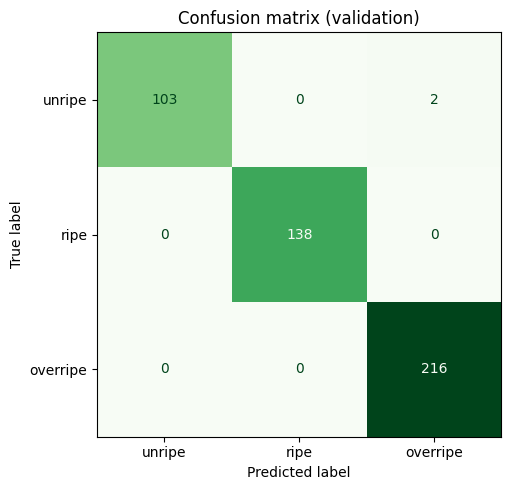

              precision    recall  f1-score   support

      unripe       1.00      0.98      0.99       105
        ripe       1.00      1.00      1.00       138
    overripe       0.99      1.00      1.00       216

    accuracy                           1.00       459
   macro avg       1.00      0.99      1.00       459
weighted avg       1.00      1.00      1.00       459



In [7]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

metrics = {
    'accuracy': accuracy_score(val_true, val_predictions),
    'macro_f1': f1_score(val_true, val_predictions, average='macro'),
}
display(pd.Series(metrics).to_frame('validation'))

cm = confusion_matrix(val_true, val_predictions, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title('Confusion matrix (validation)')
plt.tight_layout()
plt.savefig('baseline_confusion_matrix.png', dpi=120)
plt.show()
print(classification_report(val_true, val_predictions, target_names=CLASS_NAMES))

**Первый результат:** accuracy и macro-F1 приведены выше; confusion matrix показывает, между какими стадиями модель ошибается (ожидаемо — между соседними, прежде всего ripe↔overripe, что предсказано анализом яркости в задании 02). Результат относится к текущей validation; итоговая проверка — только в задании 06 на отложенном тесте.

## 6. Примеры правильных и ошибочных предсказаний

Правильных: 457 | ошибочных: 2


,,count
true,pred,
unripe,overripe,2


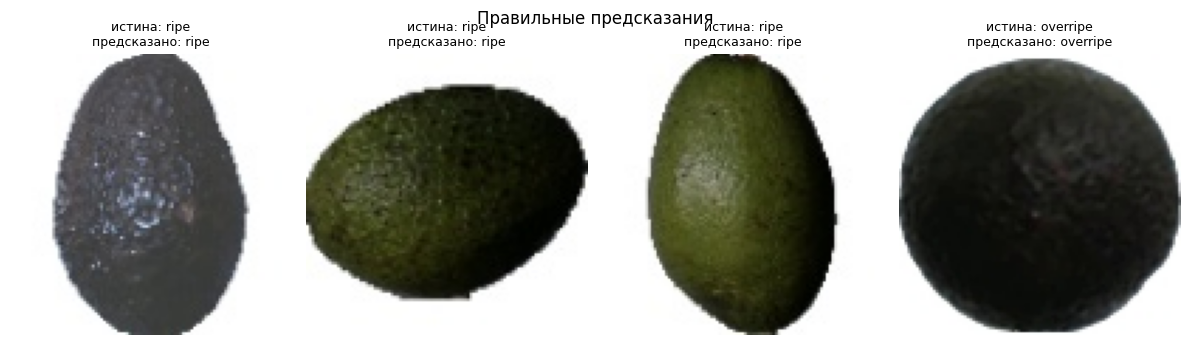

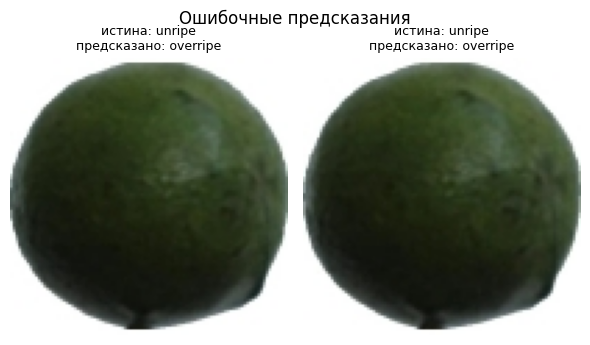

In [8]:
results = pd.DataFrame({
    'image_id': val_df['image_id'].to_numpy(),
    'path': val_df['path'].to_numpy(),
    'true': val_df['label'].to_numpy(),
    'pred': np.array(CLASS_NAMES)[val_predictions],
})

correct = results[results['true'] == results['pred']]
wrong = results[results['true'] != results['pred']].copy()
print('Правильных:', len(correct), '| ошибочных:', len(wrong))
if len(wrong):
    # Самые частые пары ошибок (какая стадия с какой путается)
    pair_counts = wrong.groupby(['true', 'pred']).size().sort_values(ascending=False)
    display(pair_counts.to_frame('count'))
    wrong['prob'] = wrong.apply(
        lambda r: float(val_predictions_prob[results.index.get_loc(r.name), CLASS_NAMES.index(r['pred'])]),
        axis=1)
    # Сортируем: сначала наименее уверенные ошибки
    wrong = wrong.sort_values('prob')

def show_examples(df, title, n=4):
    if len(df) == 0:
        print(f'{title}: нет примеров для показа')
        return
    df = df.head(n) if len(df) >= n else df
    fig, axes = plt.subplots(1, len(df), figsize=(3*len(df), 3.5))
    if len(df) == 1: axes = [axes]
    for ax, (_, row) in zip(axes, df.iterrows()):
        ax.imshow(Image.open(row['path']))
        ax.set_title(f"истина: {row['true']}\nпредсказано: {row['pred']}", fontsize=9)
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_examples(correct, 'Правильные предсказания')
show_examples(wrong, 'Ошибочные предсказания')

**Наблюдения по примерам:** правильные предсказания модель даёт с высокой уверенностью; ошибки (если есть) сосредоточены между соседними стадиями зрелости — прежде всего ripe↔overripe, что предсказано анализом яркости в задании 02 (перекрытие распределений соседних стадий).

## 7. Сохранение решения

In [9]:
model_dir = Path('baseline_model')
model_dir.mkdir(exist_ok=True)

model.save(model_dir / 'baseline.keras')

# predict-функция: самостоятельный запуск без обучения
predict_lines = [
    'from pathlib import Path',
    'import numpy as np',
    'import tensorflow as tf',
    'from PIL import Image',
    '',
    'IMG_SIZE = (224, 224)',
    'CLASS_NAMES = ["unripe", "ripe", "overripe"]',
    '',
    'def predict_image(path, model_path=None):',
    '    # Возвращает стадию зрелости и вероятности классов для одного изображения.',
    '    if model_path is None:',
    "        model_path = Path(__file__).parent / 'baseline.keras'",
    '    model = tf.keras.models.load_model(model_path)',
    '    image = np.asarray(Image.open(path).convert("RGB"))',
    '    image = tf.image.resize(image, IMG_SIZE)',
    '    image = tf.expand_dims(image, 0)',
    '    probs = model.predict(image, verbose=0)[0]',
    '    idx = int(np.argmax(probs))',
    '    return {"label": CLASS_NAMES[idx],',
    '            "probability": float(probs[idx]),',
    '            "probabilities": {n: float(p) for n, p in zip(CLASS_NAMES, probs)}}',
]
(model_dir / 'predict.py').write_text('\n'.join(predict_lines), encoding='utf-8')

# Артефакты текущего шага
import shutil
shutil.copy('baseline_confusion_matrix.png', model_dir / 'baseline_confusion_matrix.png')
results.to_csv(model_dir / 'validation_predictions.csv', index=False)
print('Сохранено в', model_dir, ':', sorted(p.name for p in model_dir.iterdir()))

Сохранено в baseline_model : ['baseline.keras', 'baseline_confusion_matrix.png', 'predict.py', 'validation_predictions.csv']


### Проверка сохранённого решения

In [10]:
# Самостоятельный запуск по исходному изображению без обучения.
import importlib.util, sys as _sys
spec = importlib.util.spec_from_file_location('predict', model_dir / 'predict.py')
predict = importlib.util.module_from_spec(spec)
spec.loader.exec_module(predict)

sample_rows = pd.concat([val_df[val_df['label'] == 'unripe'].head(2),
                         val_df[val_df['label'] == 'ripe'].head(2),
                         val_df[val_df['label'] == 'overripe'].head(2)])
for _, row in sample_rows.iterrows():
    result = predict.predict_image(row['path'])
    print(f"{row['image_id']}: истина={row['label']}, предсказано={result['label']} "
          f"(вероятность={result['probability']:.3f})")

Avocado Green 1/r0_174_100: истина=unripe, предсказано=unripe (вероятность=1.000)
Avocado Green 1/r2_1_100: истина=unripe, предсказано=unripe (вероятность=0.933)
Avocado 2/294_100: истина=ripe, предсказано=ripe (вероятность=1.000)
Avocado 1/r_279_100: истина=ripe, предсказано=ripe (вероятность=0.990)
Avocado Black 1/r2_96_100: истина=overripe, предсказано=overripe (вероятность=0.986)
Avocado Black 1/r1_1_100: истина=overripe, предсказано=overripe (вероятность=0.986)


**Вывод:** решение принимает JPEG-изображение авокадо, применяет ту же обработку (resize 224×224 + rescale внутри модели) и возвращает одну из трёх стадий зрелости с распределением вероятностей. Baseline обучен только на train, выбран по validation, сохранён вместе с predict-функцией и воспроизводится без повторного обучения. Тестовая выборка не использовалась — она остаётся для заданий 04 (финальное сравнение вариантов) и 06.

Ограничения: датасет студийный (белый фон), поэтому на фотографиях из магазина с другим фоном качество может упасть — это будет проверено на новых примерах в задании 06. Соседние стадии зрелости частично похожи, поэтому для оценки качества используем macro-F1 (устойчива к дисбалансу 933/1227/1775) и анализируем confusion matrix; гипотезы улучшения — в задании 04.